# EXP-6 — ConvNeXt-Tiny: Augmentation + Gentle Full Fine-tuning

**Mục tiêu:** tiếp tục từ checkpoint tốt nhất của EXP-3, không đổi backbone, tập trung xử lý **overfitting + domain robustness + class imbalance**.

Các thay đổi chính:
1. Augmentation thực tế cho face/deepfake: JPEG compression, Gaussian blur, Gaussian noise, ColorJitter nhẹ, horizontal flip.
2. Không dùng augmentation trên validation.
3. Fine-tuning **nhẹ toàn backbone** với discriminative learning rate, thay vì LR rất cao của EXP-5.
4. Giảm label smoothing và weight decay để tránh underfitting.
5. Giữ mini-batch gradient descent (`batch_size=64`), AMP, channels-last, non-blocking transfer.
6. Gradient clipping để ổn định cập nhật.
7. Head dùng **GELU** (phù hợp ConvNeXt) và Dropout; không thay GELU toàn backbone bằng activation khác.
8. ConvNeXt vốn dùng **LayerNorm**, vì vậy không chèn BatchNorm tùy tiện vào backbone. Một tùy chọn BatchNorm ở classification head được để sẵn cho ablation, mặc định **OFF**.
9. Theo dõi Accuracy, Precision, Recall, F1, ROC-AUC, Loss và confusion matrix.
10. Tối ưu threshold trên validation **chỉ để phân tích**. Tập test hoàn toàn không được truy cập trong EXP-6.

> **Quan trọng:** EXP-5 đạt train F1 rất cao nhưng validation thấp hơn, cho thấy overfitting; đồng thời LR `1e-4/3e-4` làm kết quả không vượt EXP-3. Vì vậy EXP-6 không tiếp tục tăng LR mà chuyển trọng tâm sang augmentation + regularization vừa phải.


In [1]:
# =========================
# 1. Install / imports
# =========================
!pip install -q torch torchvision torchaudio pandas numpy matplotlib seaborn scikit-learn tqdm

import os, gc, json, time, copy, random, shutil, zipfile, io, math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageFile
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from torchvision import transforms
from torchvision.models import convnext_tiny, ConvNeXt_Tiny_Weights

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix
)

ImageFile.LOAD_TRUNCATED_IMAGES = True
print("PyTorch:", torch.__version__)


PyTorch: 2.11.0+cu128


In [2]:
# =========================
# 2. Reproducibility + device
# =========================
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if device.type == "cuda":
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print(f"GPU memory: {torch.cuda.get_device_properties(0).total_memory/1024**3:.2f} GB")


Device: cuda
GPU: Tesla T4
GPU memory: 14.56 GB


In [3]:
# =========================
# 3. Google Drive + paths
# =========================
from google.colab import drive
drive.mount("/content/drive")

DRIVE_ROOT = "/content/drive/MyDrive"
ZIP_PATH = os.path.join(DRIVE_ROOT, "face_frames.zip")
EXTRACT_DIR = "/content/faceforensics"

EXPERIMENT_DIR = os.path.join(DRIVE_ROOT, "FaceForensics_Experiments")
FINETUNE_DIR = os.path.join(EXPERIMENT_DIR, "finetune_convnext_tiny")
CHECKPOINT_DIR = os.path.join(FINETUNE_DIR, "checkpoints")
HISTORY_DIR = os.path.join(FINETUNE_DIR, "histories")
RESULT_DIR = os.path.join(FINETUNE_DIR, "results")
BEST_TRACKER_PATH = os.path.join(FINETUNE_DIR, "best_tracker.json")

for d in [EXPERIMENT_DIR, FINETUNE_DIR, CHECKPOINT_DIR, HISTORY_DIR, RESULT_DIR]:
    os.makedirs(d, exist_ok=True)

print("ZIP:", ZIP_PATH)
print("Extract:", EXTRACT_DIR)
print("Best tracker:", BEST_TRACKER_PATH)


Mounted at /content/drive
ZIP: /content/drive/MyDrive/face_frames.zip
Extract: /content/faceforensics
Best tracker: /content/drive/MyDrive/FaceForensics_Experiments/finetune_convnext_tiny/best_tracker.json


In [4]:
# =========================
# 4. Extract dataset if needed
# =========================
if not os.path.exists(EXTRACT_DIR):
    print("Extracting dataset...")
    t0 = time.time()
    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall(EXTRACT_DIR)
    print(f"Done in {time.time()-t0:.1f}s")
else:
    print("Dataset already extracted; skip.")


Extracting dataset...
Done in 41.4s


In [5]:
# =========================
# 5. Locate train / val only
# =========================
def find_dataset_root(base_dir):
    candidates = []
    for root, dirs, files in os.walk(base_dir):
        names = {d.lower() for d in dirs}
        if {"train", "val"}.issubset(names):
            candidates.append(root)
    if not candidates:
        raise FileNotFoundError("Không tìm thấy thư mục train/val.")
    return candidates[0]

DATA_DIR = find_dataset_root(EXTRACT_DIR)
TRAIN_DIR = os.path.join(DATA_DIR, "train")
VAL_DIR = os.path.join(DATA_DIR, "val")

print(DATA_DIR)
print(TRAIN_DIR)
print(VAL_DIR)


/content/faceforensics/face_frames
/content/faceforensics/face_frames/train
/content/faceforensics/face_frames/val


In [6]:
# =========================
# 6. Configuration
# =========================
IMG_SIZE = 224
BATCH_SIZE = 64
EPOCHS = 12
EARLY_STOPPING_PATIENCE = 4

# Gentle discriminative LR — intentionally much lower than EXP-5.
LR_STAGE1 = 1e-6
LR_STAGE2 = 2e-6
LR_STAGE3 = 5e-6
LR_STAGE4_HEAD = 1e-5

WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.05
DROPOUT_P = 0.25
GRAD_CLIP_NORM = 1.0

# Loss choice:
# "unweighted" is the main experiment because EXP-5 already used strong
# inverse-frequency weights and accuracy remained low.
# "weighted" can be switched on for an ablation.
LOSS_MODE = "unweighted"

# Optional head BatchNorm. OFF by default.
# ConvNeXt backbone itself should keep LayerNorm.
USE_BATCHNORM_HEAD = False

# ConvNeXt keeps its pretrained GELU activations; do not replace them blindly.

# Augmentation strengths
JPEG_P = 0.35
BLUR_P = 0.20
NOISE_P = 0.20
COLOR_P = 0.40
ROTATION_DEG = 7

NUM_WORKERS = 2
PIN_MEMORY = device.type == "cuda"
PERSISTENT_WORKERS = NUM_WORKERS > 0
PREFETCH_FACTOR = 2
USE_AMP = device.type == "cuda"

EXP_NAME = "exp6_aug_gentle_fullft"
MODEL_NAME = "convnext_tiny"

print({
    "batch": BATCH_SIZE,
    "epochs": EPOCHS,
    "LRs": [LR_STAGE1, LR_STAGE2, LR_STAGE3, LR_STAGE4_HEAD],
    "loss": LOSS_MODE,
    "dropout": DROPOUT_P,
    "batchnorm_head": USE_BATCHNORM_HEAD,
        "AMP": USE_AMP
})


{'batch': 64, 'epochs': 12, 'LRs': [1e-06, 2e-06, 5e-06, 1e-05], 'loss': 'unweighted', 'dropout': 0.25, 'batchnorm_head': False, 'AMP': True}


In [7]:
# =========================
# 7. Dataset
# =========================
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
CLASS_TO_LABEL = {"REAL": 0, "FAKE": 1}
LABEL_TO_CLASS = {0: "REAL", 1: "FAKE"}

def create_dataframe(split_dir):
    records = []
    for class_dir in Path(split_dir).iterdir():
        if not class_dir.is_dir():
            continue
        class_name = class_dir.name.upper()
        if class_name not in CLASS_TO_LABEL:
            continue
        label = CLASS_TO_LABEL[class_name]
        for p in class_dir.rglob("*"):
            if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS:
                records.append({
                    "image_path": str(p),
                    "label": label,
                    "class_name": class_name
                })
    return pd.DataFrame(records)

train_df = create_dataframe(TRAIN_DIR)
val_df = create_dataframe(VAL_DIR)

print("TRAIN:", len(train_df))
print(train_df["class_name"].value_counts())
print("\nVAL:", len(val_df))
print(val_df["class_name"].value_counts())


TRAIN: 54346
class_name
FAKE    46448
REAL     7898
Name: count, dtype: int64

VAL: 7002
class_name
FAKE    5982
REAL    1020
Name: count, dtype: int64


In [8]:
# =========================
# 8. Custom image augmentations
# =========================
class RandomJPEGCompression:
    def __init__(self, p=0.35, quality_range=(40, 70)):
        self.p = p
        self.quality_range = quality_range

    def __call__(self, img):
        if random.random() > self.p:
            return img
        q = random.randint(*self.quality_range)
        buffer = io.BytesIO()
        img.convert("RGB").save(buffer, format="JPEG", quality=q)
        buffer.seek(0)
        return Image.open(buffer).convert("RGB")

class RandomGaussianNoise:
    def __init__(self, p=0.20, sigma_range=(0.01, 0.035)):
        self.p = p
        self.sigma_range = sigma_range

    def __call__(self, tensor):
        if random.random() > self.p:
            return tensor
        sigma = random.uniform(*self.sigma_range)
        noise = torch.randn_like(tensor) * sigma
        return torch.clamp(tensor + noise, 0.0, 1.0)

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(ROTATION_DEG),
    transforms.ColorJitter(
        brightness=0.12, contrast=0.12,
        saturation=0.10, hue=0.025
    ),
    RandomJPEGCompression(JPEG_P, (40, 70)),
    transforms.ToTensor(),
    RandomGaussianNoise(NOISE_P, (0.01, 0.035)),
    transforms.RandomApply(
        [transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.0))],
        p=BLUR_P
    ),
    transforms.Normalize([0.485,0.456,0.406],
                         [0.229,0.224,0.225])
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],
                         [0.229,0.224,0.225])
])

print("Augmentation pipeline ready.")


Augmentation pipeline ready.


In [9]:
# =========================
# 9. DataLoader — mini-batch + vectorized tensor batches
# =========================
class FaceForensicsDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        try:
            img = Image.open(row["image_path"]).convert("RGB")
            if self.transform is not None:
                img = self.transform(img)
            return img, int(row["label"])
        except Exception as e:
            raise RuntimeError(f"Cannot read {row['image_path']}: {e}")

train_dataset = FaceForensicsDataset(train_df, train_transform)
val_dataset = FaceForensicsDataset(val_df, eval_transform)

loader_kwargs = dict(
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=PERSISTENT_WORKERS,
    prefetch_factor=PREFETCH_FACTOR if NUM_WORKERS > 0 else None
)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, **loader_kwargs
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, **loader_kwargs
)

print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))


Train batches: 850
Val batches: 110


In [10]:
# =========================
# 10. Load BEST checkpoint from previous experiments
# =========================
if not os.path.exists(BEST_TRACKER_PATH):
    raise FileNotFoundError(
        "Không có best_tracker.json. Hãy chạy các EXP trước đó trước."
    )

with open(BEST_TRACKER_PATH, "r") as f:
    best_tracker = json.load(f)

CURRENT_BEST_CHECKPOINT = best_tracker["checkpoint"]

print("Source experiment:", best_tracker.get("source_exp"))
print("Checkpoint:", CURRENT_BEST_CHECKPOINT)
print("Previous best F1:", best_tracker.get("best_val_f1"))
print("Previous best AUC:", best_tracker.get("best_val_roc_auc"))
print("Previous best Accuracy:", best_tracker.get("best_val_accuracy"))

if not os.path.exists(CURRENT_BEST_CHECKPOINT):
    raise FileNotFoundError(CURRENT_BEST_CHECKPOINT)


Source experiment: exp3_cosine_scheduler
Checkpoint: /content/drive/MyDrive/FaceForensics_Experiments/finetune_convnext_tiny/checkpoints/convnext_tiny_exp3_cosine_scheduler_best.pth
Previous best F1: 0.9259626508015204
Previous best AUC: 0.7684449590601871
Previous best Accuracy: 0.8720365609825764


In [11]:
# =========================
# 11. ConvNeXt-Tiny model + safe classifier head
# =========================
class ConvNeXtHead(nn.Module):
    def __init__(self, in_features, dropout=0.20, use_batchnorm=False):
        super().__init__()
        self.bn = nn.BatchNorm1d(in_features) if use_batchnorm else nn.Identity()
        self.dropout = nn.Dropout(dropout)
        # Keep the original 768 -> 2 classifier shape so the EXP-3 classifier
        # can be reused instead of throwing away its learned decision boundary.
        self.fc = nn.Linear(in_features, 2, bias=True)

    def forward(self, x):
        x = self.bn(x)
        x = self.dropout(x)
        return self.fc(x)

def build_model():
    model = convnext_tiny(weights=ConvNeXt_Tiny_Weights.DEFAULT)
    in_features = model.classifier[-1].in_features

    model.classifier = nn.Sequential(
        model.classifier[0],  # LayerNorm2d
        model.classifier[1],  # Flatten
        ConvNeXtHead(
            in_features,
            dropout=DROPOUT_P,
            use_batchnorm=USE_BATCHNORM_HEAD
        )
    )
    return model

model = build_model()

checkpoint = torch.load(
    CURRENT_BEST_CHECKPOINT, map_location="cpu", weights_only=False
)
state = checkpoint.get("model_state_dict", checkpoint)

# Load all backbone weights.
backbone_state = {
    k: v for k, v in state.items()
    if not k.startswith("classifier.")
}
missing, unexpected = model.load_state_dict(backbone_state, strict=False)

# Reuse the learned EXP-3 classifier when its 768 -> 2 weights exist.
old_linear_w = state.get("classifier.2.weight")
old_linear_b = state.get("classifier.2.bias")

if old_linear_w is None:
    old_linear_w = state.get("classifier.3.weight")
    old_linear_b = state.get("classifier.3.bias")

if old_linear_w is not None and tuple(old_linear_w.shape) == tuple(model.classifier[2].fc.weight.shape):
    with torch.no_grad():
        model.classifier[2].fc.weight.copy_(old_linear_w)
        model.classifier[2].fc.bias.copy_(old_linear_b)
    print("✓ Reused pretrained EXP-3 classifier weights.")
else:
    print("! Old classifier shape not found; classifier remains randomly initialized.")

print("Loaded pretrained backbone from:", CURRENT_BEST_CHECKPOINT)
print("Missing keys after backbone load:", len(missing))
print("Unexpected keys:", len(unexpected))
print(model.classifier)


Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 179MB/s] 


✓ Reused pretrained EXP-3 classifier weights.
Loaded pretrained backbone from: /content/drive/MyDrive/FaceForensics_Experiments/finetune_convnext_tiny/checkpoints/convnext_tiny_exp3_cosine_scheduler_best.pth
Missing keys after backbone load: 4
Unexpected keys: 0
Sequential(
  (0): LayerNorm2d((768,), eps=1e-06, elementwise_affine=True)
  (1): Flatten(start_dim=1, end_dim=-1)
  (2): ConvNeXtHead(
    (bn): Identity()
    (dropout): Dropout(p=0.25, inplace=False)
    (fc): Linear(in_features=768, out_features=2, bias=True)
  )
)


In [12]:
# =========================
# 12. Progressive unfreezing policy
# =========================
# EXP-5 froze early layers and used very high LR.
# Here: all stages are trainable, but early layers move extremely slowly.

for p in model.parameters():
    p.requires_grad = True

model = model.to(device)

if device.type == "cuda":
    model = model.to(memory_format=torch.channels_last)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Total params: {total_params/1e6:.2f}M")
print(f"Trainable params: {trainable_params/1e6:.2f}M")
print(model.classifier)


Total params: 27.82M
Trainable params: 27.82M
Sequential(
  (0): LayerNorm2d((768,), eps=1e-06, elementwise_affine=True)
  (1): Flatten(start_dim=1, end_dim=-1)
  (2): ConvNeXtHead(
    (bn): Identity()
    (dropout): Dropout(p=0.25, inplace=False)
    (fc): Linear(in_features=768, out_features=2, bias=True)
  )
)


In [13]:
# =========================
# 13. Loss — compare unweighted vs weighted
# =========================
class_counts = train_df["label"].value_counts().sort_index()
print("Class counts:", class_counts.to_dict())

if LOSS_MODE == "weighted":
    weights = []
    total = len(train_df)
    for label in range(2):
        weights.append(total / (2 * class_counts[label]))
    class_weights = torch.tensor(weights, dtype=torch.float32, device=device)
    print("Class weights:", class_weights.tolist())
else:
    class_weights = None
    print("Using UNWEIGHTED CrossEntropyLoss.")

criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=LABEL_SMOOTHING
)
print(criterion)


Class counts: {0: 7898, 1: 46448}
Using UNWEIGHTED CrossEntropyLoss.
CrossEntropyLoss()


In [14]:
# =========================
# 14. Discriminative optimizer
# =========================
features = model.features

param_groups = [
    {
        "params": list(features[0].parameters()),
        "lr": LR_STAGE1,
        "name": "stage1"
    },
    {
        "params": list(features[1].parameters()) + list(features[2].parameters()),
        "lr": LR_STAGE2,
        "name": "stage2"
    },
    {
        "params": list(features[3].parameters()) + list(features[4].parameters()) + list(features[5].parameters()),
        "lr": LR_STAGE3,
        "name": "stage3"
    },
    {
        "params": list(features[6].parameters()) + list(features[7].parameters()) +
                  list(model.avgpool.parameters()) + list(model.classifier.parameters()),
        "lr": LR_STAGE4_HEAD,
        "name": "stage4+head"
    }
]

optimizer = torch.optim.AdamW(
    param_groups,
    weight_decay=WEIGHT_DECAY,
    betas=(0.9, 0.999)
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS, eta_min=1e-7
)

for g in param_groups:
    n = sum(p.numel() for p in g["params"])
    print(f"{g['name']:12s} | LR={g['lr']:.1e} | Params={n/1e6:.2f}M")


stage1       | LR=1.0e-06 | Params=0.00M
stage2       | LR=2.0e-06 | Params=0.31M
stage3       | LR=5.0e-06 | Params=12.03M
stage4+head  | LR=1.0e-05 | Params=15.47M


In [15]:
# =========================
# 15. Training / validation functions
# =========================
def move_images(images):
    images = images.to(device, non_blocking=True)
    if device.type == "cuda":
        images = images.contiguous(memory_format=torch.channels_last)
    return images

def train_one_epoch(model, loader):
    model.train()
    running_loss = 0.0
    all_preds, all_labels = [], []

    for images, labels in tqdm(loader, desc="Train", leave=False):
        images = move_images(images)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(device_type=device.type, enabled=USE_AMP):
            logits = model(images)
            loss = criterion(logits, labels)

        if USE_AMP:
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
            optimizer.step()

        running_loss += loss.item() * images.size(0)
        preds = logits.argmax(dim=1)

        all_preds.append(preds.detach().cpu())
        all_labels.append(labels.detach().cpu())

    y_pred = torch.cat(all_preds).numpy()
    y_true = torch.cat(all_labels).numpy()

    return (
        running_loss / len(loader.dataset),
        f1_score(y_true, y_pred, pos_label=1, zero_division=0)
    )

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    running_loss = 0.0
    all_probs, all_preds, all_labels = [], [], []

    for images, labels in tqdm(loader, desc="Eval", leave=False):
        images = move_images(images)
        labels = labels.to(device, non_blocking=True)

        with torch.amp.autocast(device_type=device.type, enabled=USE_AMP):
            logits = model(images)
            loss = criterion(logits, labels)

        probs = torch.softmax(logits, dim=1)[:, 1]
        preds = (probs >= 0.5).long()

        running_loss += loss.item() * images.size(0)
        all_probs.append(probs.cpu())
        all_preds.append(preds.cpu())
        all_labels.append(labels.cpu())

    y_prob = torch.cat(all_probs).numpy()
    y_pred = torch.cat(all_preds).numpy()
    y_true = torch.cat(all_labels).numpy()

    return {
        "loss": running_loss / len(loader.dataset),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "f1": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "y_true": y_true,
        "y_pred": y_pred,
        "y_prob": y_prob
    }


In [16]:
# =========================
# 16. Train
# =========================
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

history = []
best_f1 = -1.0
best_auc = -1.0
best_epoch = -1
epochs_without_improvement = 0

EXP6_CHECKPOINT = os.path.join(
    CHECKPOINT_DIR, f"{MODEL_NAME}_{EXP_NAME}_best.pth"
)
EXP6_HISTORY = os.path.join(
    HISTORY_DIR, f"{MODEL_NAME}_{EXP_NAME}_history.csv"
)

total_start = time.time()

for epoch in range(EPOCHS):
    t0 = time.time()
    print("\n" + "="*70)
    print(f"Epoch {epoch+1}/{EPOCHS}")

    train_loss, train_f1 = train_one_epoch(model, train_loader)
    val = evaluate(model, val_loader)

    scheduler.step()
    lrs = [g["lr"] for g in optimizer.param_groups]

    row = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_f1": train_f1,
        "val_loss": val["loss"],
        "val_accuracy": val["accuracy"],
        "val_precision": val["precision"],
        "val_recall": val["recall"],
        "val_f1": val["f1"],
        "val_roc_auc": val["roc_auc"],
        "lr_stage1": lrs[0],
        "lr_stage2": lrs[1],
        "lr_stage3": lrs[2],
        "lr_stage4_head": lrs[3],
        "epoch_time_sec": time.time()-t0
    }
    history.append(row)

    print(f"Train Loss : {train_loss:.4f}")
    print(f"Train F1   : {train_f1:.4f}")
    print(f"Val Loss   : {val['loss']:.4f}")
    print(f"Val Acc    : {val['accuracy']:.4f}")
    print(f"Val Prec   : {val['precision']:.4f}")
    print(f"Val Recall : {val['recall']:.4f}")
    print(f"Val F1     : {val['f1']:.4f}")
    print(f"Val AUC    : {val['roc_auc']:.4f}")
    print(f"Epoch time : {row['epoch_time_sec']:.1f}s")

    # Primary selection = F1, tie-break = ROC-AUC
    better = (val["f1"] > best_f1) or (
        val["f1"] == best_f1 and val["roc_auc"] > best_auc
    )

    if better:
        best_f1 = val["f1"]
        best_auc = val["roc_auc"]
        best_epoch = epoch + 1
        epochs_without_improvement = 0

        torch.save({
            "model_name": MODEL_NAME,
            "exp_name": EXP_NAME,
            "finetuned_from": CURRENT_BEST_CHECKPOINT,
            "epoch": best_epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict() if USE_AMP else None,
            "metrics": {k:v for k,v in val.items() if k not in ["y_true","y_pred","y_prob"]},
            "config": {
                "img_size": IMG_SIZE,
                "batch_size": BATCH_SIZE,
                "epochs": EPOCHS,
                "lr_stage1": LR_STAGE1,
                "lr_stage2": LR_STAGE2,
                "lr_stage3": LR_STAGE3,
                "lr_stage4_head": LR_STAGE4_HEAD,
                "weight_decay": WEIGHT_DECAY,
                "label_smoothing": LABEL_SMOOTHING,
                "dropout": DROPOUT_P,
                "loss_mode": LOSS_MODE,
                "batchnorm_head": USE_BATCHNORM_HEAD,
                        "seed": SEED
            }
        }, EXP6_CHECKPOINT)
        print("✓ BEST CHECKPOINT SAVED")
    else:
        epochs_without_improvement += 1
        print(f"No improvement: {epochs_without_improvement}/{EARLY_STOPPING_PATIENCE}")

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("Early stopping.")
        break

history_df = pd.DataFrame(history)
history_df.to_csv(EXP6_HISTORY, index=False)

print("\nFinished.")
print("Best epoch:", best_epoch)
print("Best F1:", best_f1)
print("Best AUC:", best_auc)
print("Time:", (time.time()-total_start)/60, "min")



Epoch 1/12


Train:   0%|          | 0/850 [00:00<?, ?it/s]

Eval:   0%|          | 0/110 [00:00<?, ?it/s]

Train Loss : 0.2181
Train F1   : 0.9793
Val Loss   : 0.4681
Val Acc    : 0.8695
Val Prec   : 0.9153
Val Recall : 0.9336
Val F1     : 0.9244
Val AUC    : 0.8177
Epoch time : 592.3s
✓ BEST CHECKPOINT SAVED

Epoch 2/12


Train:   0%|          | 0/850 [00:00<?, ?it/s]

...

Eval:   0%|          | 0/110 [00:00<?, ?it/s]

Train Loss : 0.1646
Train F1   : 0.9855
Val Loss   : 0.4857
Val Acc    : 0.8713
Val Prec   : 0.9129
Val Recall : 0.9390
Val F1     : 0.9258
Val AUC    : 0.8110
Epoch time : 511.3s
No improvement: 3/4

Epoch 9/12


Train:   0%|          | 0/850 [00:00<?, ?it/s]

Eval:   0%|          | 0/110 [00:00<?, ?it/s]

Train Loss : 0.1630
Train F1   : 0.9864
Val Loss   : 0.4869
Val Acc    : 0.8698
Val Prec   : 0.9137
Val Recall : 0.9360
Val F1     : 0.9247
Val AUC    : 0.8193
Epoch time : 509.4s
No improvement: 4/4
Early stopping.

Finished.
Best epoch: 5
Best F1: 0.9260719566288812
Best AUC: 0.814464963518005
Time: 79.16810632546743 min


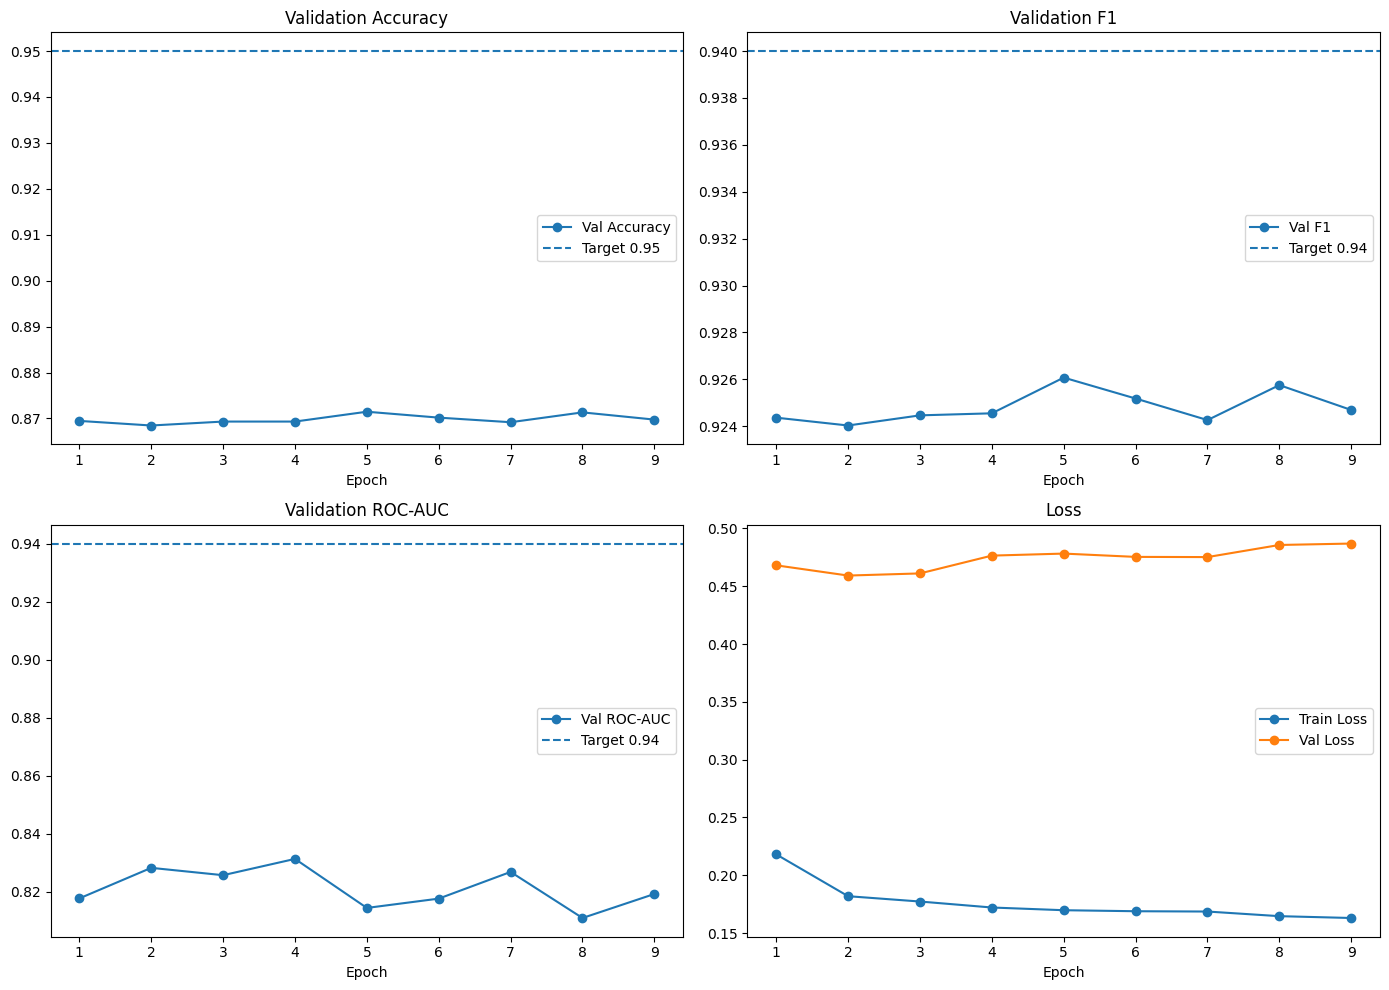

In [17]:
# =========================
# 17. Curves
# =========================
h = pd.read_csv(EXP6_HISTORY)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

axes[0].plot(h["epoch"], h["val_accuracy"], marker="o", label="Val Accuracy")
axes[0].axhline(0.95, linestyle="--", label="Target 0.95")
axes[0].set_title("Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(h["epoch"], h["val_f1"], marker="o", label="Val F1")
axes[1].axhline(0.94, linestyle="--", label="Target 0.94")
axes[1].set_title("Validation F1")
axes[1].set_xlabel("Epoch")
axes[1].legend()

axes[2].plot(h["epoch"], h["val_roc_auc"], marker="o", label="Val ROC-AUC")
axes[2].axhline(0.94, linestyle="--", label="Target 0.94")
axes[2].set_title("Validation ROC-AUC")
axes[2].set_xlabel("Epoch")
axes[2].legend()

axes[3].plot(h["epoch"], h["train_loss"], marker="o", label="Train Loss")
axes[3].plot(h["epoch"], h["val_loss"], marker="o", label="Val Loss")
axes[3].set_title("Loss")
axes[3].set_xlabel("Epoch")
axes[3].legend()

plt.tight_layout()
plt.show()


Eval:   0%|          | 0/110 [00:00<?, ?it/s]

BEST EXP-6 — VALIDATION
loss      : 0.4782
accuracy  : 0.8715
precision : 0.9104
recall    : 0.9423
f1        : 0.9261
roc_auc   : 0.8145


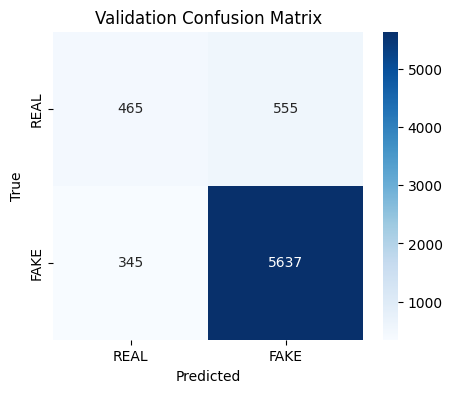

In [18]:
# =========================
# 18. Load best EXP-6 and evaluate VAL
# =========================
best_ckpt = torch.load(EXP6_CHECKPOINT, map_location=device, weights_only=False)
model.load_state_dict(best_ckpt["model_state_dict"])

val_best = evaluate(model, val_loader)

print("BEST EXP-6 — VALIDATION")
for k in ["loss","accuracy","precision","recall","f1","roc_auc"]:
    print(f"{k:10s}: {val_best[k]:.4f}")

cm = confusion_matrix(val_best["y_true"], val_best["y_pred"])
plt.figure(figsize=(5,4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["REAL","FAKE"],
    yticklabels=["REAL","FAKE"]
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Validation Confusion Matrix")
plt.show()


Best threshold by validation Accuracy:
threshold    0.220000
accuracy     0.876035
precision    0.904205
recall       0.956202
f1           0.929477
Name: 2, dtype: float64

Best threshold by validation F1:
threshold    0.200000
accuracy     0.875893
precision    0.903043
recall       0.957539
f1           0.929493
Name: 0, dtype: float64


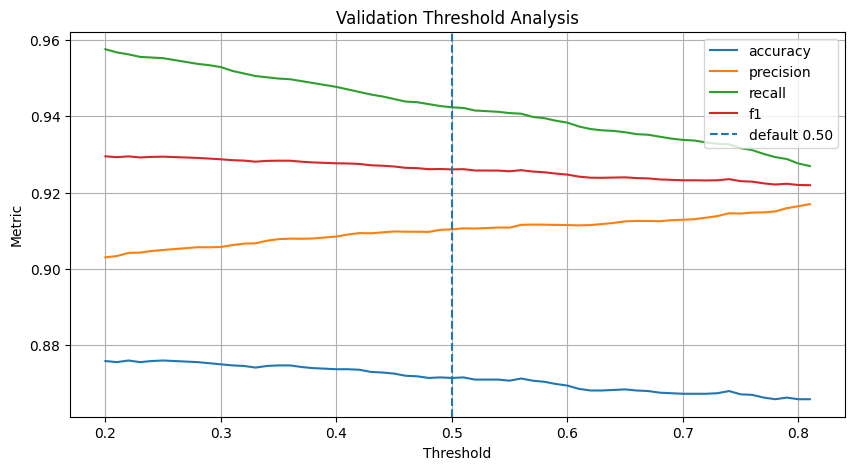

In [19]:
# =========================
# 19. Threshold analysis on VALIDATION only
# =========================
threshold_rows = []

for t in np.arange(0.20, 0.81, 0.01):
    pred = (val_best["y_prob"] >= t).astype(int)
    threshold_rows.append({
        "threshold": t,
        "accuracy": accuracy_score(val_best["y_true"], pred),
        "precision": precision_score(val_best["y_true"], pred, zero_division=0),
        "recall": recall_score(val_best["y_true"], pred, zero_division=0),
        "f1": f1_score(val_best["y_true"], pred, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_rows)

best_acc_row = threshold_df.loc[threshold_df["accuracy"].idxmax()]
best_f1_row = threshold_df.loc[threshold_df["f1"].idxmax()]

print("Best threshold by validation Accuracy:")
print(best_acc_row)

print("\nBest threshold by validation F1:")
print(best_f1_row)

plt.figure(figsize=(10,5))
for col in ["accuracy","precision","recall","f1"]:
    plt.plot(threshold_df["threshold"], threshold_df[col], label=col)
plt.axvline(0.5, linestyle="--", label="default 0.50")
plt.xlabel("Threshold")
plt.ylabel("Metric")
plt.title("Validation Threshold Analysis")
plt.legend()
plt.grid(True)
plt.show()


In [20]:
# =========================
# 21. Save EXP-6 summary
# =========================
summary = {
    "experiment": EXP_NAME,
    "model": MODEL_NAME,
    "source_checkpoint": CURRENT_BEST_CHECKPOINT,
    "best_checkpoint": EXP6_CHECKPOINT,
    "best_epoch": int(best_epoch),
    "val_metrics_at_0.5": {
        k: float(val_best[k]) for k in
        ["loss","accuracy","precision","recall","f1","roc_auc"]
    },
    "validation_selected_threshold": selected_threshold,
    "config": {
        "batch_size": BATCH_SIZE,
        "epochs_planned": EPOCHS,
        "lr_stage1": LR_STAGE1,
        "lr_stage2": LR_STAGE2,
        "lr_stage3": LR_STAGE3,
        "lr_stage4_head": LR_STAGE4_HEAD,
        "weight_decay": WEIGHT_DECAY,
        "label_smoothing": LABEL_SMOOTHING,
        "dropout": DROPOUT_P,
        "loss_mode": LOSS_MODE,
        "use_batchnorm_head": USE_BATCHNORM_HEAD,
        "jpeg_p": JPEG_P,
        "blur_p": BLUR_P,
        "noise_p": NOISE_P,
        "seed": SEED
    }
}

summary_path = os.path.join(
    RESULT_DIR, f"{MODEL_NAME}_{EXP_NAME}_summary.json"
)

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

print("Saved:", summary_path)


NameError: name 'selected_threshold' is not defined

## Cách đọc kết quả EXP-6

- **Train F1 tăng rất cao nhưng Val F1 giảm** → vẫn overfit: tăng augmentation/weight decay hoặc giảm số epoch.
- **Val F1 tăng nhưng Accuracy không tăng** → kiểm tra class imbalance và threshold; xem confusion matrix.
- **ROC-AUC tăng rõ** → representation tốt hơn, dù threshold 0.5 chưa tối ưu.
- **Accuracy và F1 cùng tăng** → đây là tín hiệu tốt nhất.
- **Nếu EXP-6 vẫn quanh 0.85–0.87 Accuracy** dù AUC/F1 tốt hơn, không nên tiếp tục tăng LR. Khi đó cần điều tra chất lượng frame, label noise, domain gap hoặc cách đánh giá frame-level.

### Lưu ý về các kỹ thuật được yêu cầu

| Kỹ thuật | Xử lý trong notebook |
|---|---|
| Data augmentation | **Có**, tập trung JPEG/blur/noise + augmentation hình học nhẹ |
| Vectorization | **Có ở cấp batch/tensor**: DataLoader tạo mini-batch, tensor ops, channels-last, AMP |
| Mini-batch gradient descent | **Có**, `BATCH_SIZE=64` |
| Bias | **Có**, các `Linear(..., bias=True)` trong head |
| Bias/variance | Theo dõi trực tiếp qua khoảng cách Train F1 ↔ Val F1 và Train Loss ↔ Val Loss |
| Dropout | **Có**, `p=0.25` |
| Activation | Giữ **GELU** có sẵn trong ConvNeXt; không thay toàn backbone tùy tiện |
| Batch Normalization | **Có tùy chọn ở head**, mặc định OFF vì ConvNeXt backbone dùng LayerNorm |
| Gradient clipping | **Có**, norm = 1.0 |
| Threshold tuning | **Có trên validation**; test được giữ nguyên cho đánh giá cuối cùng |

### Protocol chống leakage
EXP-6 chỉ sử dụng `train/` để cập nhật trọng số và `val/` để đánh giá, early stopping, chọn checkpoint và phân tích threshold. Tập test không được đọc hoặc đánh giá trong experiment này; chỉ sử dụng sau khi quá trình fine-tuning và lựa chọn model đã hoàn tất.
